# Credit Spread for a Basket Product (CR)

## CQF Final Project, Topic:CR, Cohort: January 2026

**Author**: Bhupendra Ramteke

This notebook prices the $k$-th to default Basket Credit Default Swap (CDS) using the Copula Method.This notebook is a project report: that includes narrative, mathematics, code and results in one document. The computation engine `basket_engine.py` is a companion module, which is available in the CODE.zip folder.

In this project, I have used established libraries. For low-discrepancy sequences `scipy.stats.qmc` (Quasi Monte Carlo) is used. For pseudo-random number generation `numpy.random.Generator` is used. For root finding and distribution fitting `scipy.optimize' has been used.

### Contents

| SNo | Section |
|:---:|:---|
| 1 | Introduction and study design |
| 2 | Mathematical underpinnings of the model |
| 3 | Numerical methods, accuracy, convergence |
| 4 | Data and calibration |
| 5 | Dependence |
| 6 | The spread ladder (Outcome) |
| 7 | Validation |
| 8 | Sensitivities |
| 9 | Extension: CSRBB / IRRBB |
| 10 | Takeaways, Weakness and the future |
|  11 | Conclusion and references |


## 1. Introduction and study Design

### 1.1 Problem statement

CDS is a Credit Default Swap. Buying a CDS means we have bought an insurance on a reference asset (for eg a bond issue). Like insurance, buying a CDS means buying a protection and thus paying a premium (more specifically CDS spread) to protection seller. The scenario that is understandable is buying a protection when you own the reference assets. So you basically transfer the credit risk to protection seller. Leading up to 2008 crisis, it was observed that a company like AIG sold CDS protections on large scale on reference assets which were notional in nature (no or limited real exposured). The challenge is whether the protection seller is adequately capitalized to make the payoff in case the defaults happen together or nearer to each other. 

A basket credit default swap is a single OTC contract that references a portfolio of obligors. The protection buyer pays a periodic spread (premium); the seller compensates the buyer when the $k$-th name defaults. This notebook prices the fair spread for the complete ladder $k$ = 1,2,3,4,5 on a five-name basket, under both a Gaussian and Student-t copula, by Monte-Carlo simulation of correlated default times.

- **1st-to-default** — Pays the first time *any* of the five fails. Then it is over — even if the other four collapse next week.
- **2nd-to-default** — Ignores the first default entirely. Pays when the second name goes.
- **5th-to-default** — Pays only if *all five* companies fail within five years.

The payout is always the same size: $(1-R) \times \tfrac{1}{5} \times N$, the loss on one name's share of the notional.

> The contract is simple - Five European reference names, EUR 2m notional each, that is EUR 10m in total. Maturity T = 5 
> years, premium paid quarterly in arrears. On the $k$-th credit event the seller pays
> $\mathrm{LGD}=(1-R)\times\tfrac15\times\ N$. I used R = 40% for everyone except Siemens (45%).

A single-name CDS curve has the information on each obligor's marginal default distribution and says nothing about whether the obligors are going to fail together. The joint distribution of the $k$-th default time has no closed form, so the copula helps provide the dependence and Monte-Carlo provides the simulations for correlated default times.


### 1.2 Study Design

1. **Marginal Distribution (SNo 4.3):** Bootstrap a 5 piecewise-constant hazard curve for each of the 5 reference names from its 1Y to 5Y CDS spreads by solving the par condition one by one.

2. **Dependence (SNo 5):** Transform three years of weekly equity returns (for the reference names) into psuedo samples $\hat U=\hat F(\text{data})$ by kernel-smoothed CDF with GPD tails; estimate the t-copula degreees of freedom $\nu$ by explicit maximum likelihood.

3. **Simulation (SNo 3, SNo 5.4):** Sample correlated uniforms from each copula using scrambled Sobol's sequence, invert each marginal survival curve for exact default time; then order them.

4. **Pricing (SNo 6):** Average the default and premium legs separately across path and take ratio once, for every $k$.

5. **Validation (SNo 7):** Four gates, culminating in an exact protection-leg identity.

6. **Risk (SNo 8 and SNo 9):** Sensitivities to correlation, single-name credit spread and recovery for all five instruments, extended to a supervisory review($\Delta$EVE reading)

**Note:** Historical CDS observations were not consistently available for all five names, so I use daily equity returns as a proxy for the dependence structure. This is admittedly an approximation, as equity and credit dependence are related but distinct. Consequently, the resulting correlation matrix should be interpreted strictly as a modeling proxy rather than a direct estimate of market-implied default correlation.


## 2. Mathematical underpinnings of the model

### 2.1 Default time, hazard rate and survival curve

Assume $\tau$ be the time at which a company defaults, it can be anything may be 1.5 years or 100 years or the default never happens. It is a random quantity. Hazard rate $\lambda$ is an instantaneous rate of default given it has survived so far.

Each obligor's default time $\tau$ is modelled as the first jump of an inhomogenous Poisson process with deterministic, piecewise-constant intensity $\lambda(t)\ge0$ — the market standard ISDA assumption.

The survival probability is given by:

$$Q(t)=\Pr(\tau>t)=\exp\!\Big(-\!\int_0^{t}\lambda_u\,du\Big)
      =\exp\!\Big(-\!\sum_{j\le m}\lambda_j\,\Delta t_j\Big)$$

**Note:** Above we can see the integral collapses into a sum as the $\lambda$ (hazard rate) is a piecewise constant that holds one value for 1st year, another for 2nd year and so on.
 
So $Q(t)$ behaves like a discount factor. For a par CDS of maturity $T$ with spread $s$, recovery $R$ and risk-free discountnfactor $Z(0,t)$, the fair spread equates the two legs:

$$\underbrace{(1-R)\sum_{i} Z(0,t_i)\big[Q(t_{i-1})-Q(t_i)\big]}_{\text{default (protection) leg}}
=\underbrace{s\sum_{i} Z(0,t_i)\,Q(t_i)\,\Delta t_i}_{\text{premium leg}}+\ \text{accrual}.$$

**Bootstrapping** solves this pillar by pillar for the hazard rates that reprice the quoted strip - similar to stripping of yield curve. Inverting the survival ratio gives us the intensity directly,


$$\lambda_m=-\frac{1}{\Delta t}\log\frac{Q(t_m)}{Q(t_{m-1})}$$


### 2.2 The copula — separating marginal distribution from dependence

The Gaussian copula, $C_{\Sigma}^{Ga}(\mathbf{u}) = \Phi_{\Sigma}(\Phi^{-1}(u_1), \dots)$, is the market baseline, and its defining property is that it has no tail dependence at all. Condition on one name being in its extreme lower tail and the probability that a second is too decays to zero as the quantile shrinks, for every $\rho < 1$. Raising $\rho$ to $0.99$ does not fix this — it only slows the decay. Joint extremes remain asymptotically independent, which is the specific mechanism by which the model understated joint default risk before 2008. My own SNo 5.4 table shows the decay in progress: $0.442$ at $q = 20\%$, $0.121$ at $q = 1\%$, still falling.

The $t$ copula, $C_{\Sigma, \nu}^{t}$, breaks that by dividing every coordinate by one shared draw $\sqrt{s/\nu}, s \sim \chi_{\nu}^{2}$. Because the same scalar rescales all five names, a large draw pushes them into their tails together, and the limit stays strictly positive:

$$\lambda_L = \lambda_U = 2 t_{\nu+1} \left( -\sqrt{\frac{(\nu + 1)(1 - \rho)}{1 + \rho}} \right) > 0.$$

How much this matters depends entirely on $\nu$, which is why SNo 5.3 estimates it rather than assuming it.

**Note**: Kendall's $\tau$ and Spearman's $\rho_s$ are rank correlation measures, i.e they are ordinal. These are not impacted by extremes and are non-parametric. 
Pearson's $\rho_p$ on other hand is a cardinal measure of correlation that is sensitive to outlier and it being 0 points to points to absence of liner relationship, not necessarily independence.


### 2.3 Obtaining correlated default time

This is obtained using inverse transform sampling. The simulation generates random number $u$ between 0 and 1, which is then coverted to default time $\tau$.

Because $Q(t)=\exp(-\Lambda(t))$ where $\Lambda(t)=\sum_j \lambda_j \Delta t_j$ is the **cumulative hazard**, the equation $Q(\tau)=u$ becomes:

$$\Lambda(\tau) = -\ln u.$$

So the process is:

1. Compute the threshold $L = -\ln u$.
2. Walk along the cumulative hazard ladder $\Lambda(1), \Lambda(2), \dots$ until we find the year $m$ where it first exceeds $L$. That is the year of default.
3. Interpolate inside that year to get the exact fraction: $\delta t = \big(L - \Lambda(t_{m-1})\big)/\lambda_m$.
4. The answer is $\tau = t_{m-1} + \delta t$.

### 2.4 $k$-th to default payoff and its fair spread

A **$k$-th-to-Default Credit Default Swap (CDS)** is a credit derivative basket containing $n$ underlying reference entities ("names"). The contract triggers a protection payout precisely at the time of the $k$-th default (e.g., $k=1$ for First-to-Default, $k=2$ for Second-to-Default). 


In a Monte Carlo framework, joint default times are simulated for all $n$ names and sorted chronologically for each sample path:

$$\tau_{(1)} \leq \tau_{(2)} \leq \dots \leq \tau_{(k)} \leq \dots \leq \tau_{(n)}$$

The contract evaluates the specific sorted default time $\tau_{(k)}$ against the maturity horizon $T$:
* **If $\tau_{(k)} \leq T$:** The protection seller pays the default loss at $\tau_{(k)}$.
* **Premium Collection:** The protection buyer pays regular credit spreads (the annuity) until $\min(\tau_{(k)}, T)$.


The fair par spread ($s_k$) equates the expected present value of the **Default Leg ($\text{DL}$)** to the **Premium Leg ($\text{PL}$)**:

$$s_k = \frac{\langle \text{DL} \rangle}{\langle \text{PL} \rangle} = \frac{(1 - R) \sum_{i} Z(0, t_i) \left[ F_k(t_i) - F_k(t_{i-1}) \right]}{\Delta t \sum_{i} Z(0, t_i) \left[ 1 - F_k(t_i) \right]}$$

Where:
* $R$ is the recovery rate.
* $Z(0, t_i)$ is the risk-free discount factor from valuation time $0$ to payment date $t_i$.
* $F_k(t_i)$ is the empirical cumulative distribution function of the $k$-th default time.
* $\Delta t$ is the accrual fraction between payment periods.

**Note** Since $F_k$ lacks a closed-form analytical expression, we must simulate sample paths. We **must average the legs independently across all paths first**, and then compute the ratio at the very end. Taking the ratio path-by-path introduces severe statistical bias.


When designing the contract, the premium structure prior to the $k$-th default must be specified:

1. **Full Notional Scaling:** Protection pays $(1 - R) \times \frac{1}{n} \times N$ while the premium buyer pays the spread on the full unadjusted portfolio notional. *(An alternative convention pays $(1-R)$ on the entire portfolio notional, yielding spreads exactly $n$ times larger).*
2. **Notional Reduction (Step-Down Annuity):** The portfolio notional reduces by $1/n$ each time *any* entity defaults. For example, in a 5-name basket ($n=5$) valuing a 2nd-to-default contract ($k=2$), the realized premium leg across a path is:

$$\text{PL}_{k=2} = Z(0, \tau_{(1)})(\tau_{(1)} - 0)\frac{5}{5} + Z(0, \tau_{(2)})(\tau_{(2)} - \tau_{(1)})\frac{4}{5}$$


The fair spreads of default baskets strictly decrease as the hurdle $k$ increases, establishing the relationship:

$$s_1 \geq s_2 \geq \dots \geq s_n$$

This property is driven by event **nesting** (for a 3rd default to happen, the 1st and 2nd defaults must have already occurred):
* **Default Leg Decreases:** Reaching higher default thresholds is statistically less probable ($\text{PV}_{\text{Protection}}$ falls as $k \uparrow$).
* **Premium Leg Increases:** The contract survives longer on average, forcing more premium payments ($\text{PV}_{\text{Annuity}}$ rises as $k \uparrow$).
* **Combined Effect:** Both forces work in tandem to depress the fair par spread $s_k$ for higher values of $k$.

## 3. Numerical methods, accuracy and convergence


#### Stepwise - Copula Sampling

##### **Gaussian**
Simulating uniform margins $\mathbf{u}$ with a target correlation matrix $\hat{\Sigma}$ takes four direct steps:
1. **Factor:** Compute $\hat{\Sigma} = A A'$ via Cholesky decomposition to capture the dependence structure.
2. **Draw:** Generate independent standard normal variables $\mathbf{z} \sim N(0, \mathbf{I}_n)$.
3. **Correlate:** Rotate the independent factors into the asset space: $\mathbf{x} = A\mathbf{z}$.
4. **Transform:** Map them into uniforms via the normal CDF: $\mathbf{u} = \Phi(\mathbf{x})$.

##### **Student-$t$**
To inject tail risk, add a shared scaling factor right before the final mapping:
* **Scale Variable:** Pull a random scalar $s$ from a Chi-squared distribution: $s \sim \chi^2_\nu$.
* **Rescale:** Divide the correlated vector by this common shock factor: $\mathbf{y} = \frac{\mathbf{x}}{\sqrt{s/\nu}}$.
* **Map:** Convert to uniforms using the Student-$t$ CDF ($T_\nu$) instead of the normal one: $\mathbf{u} = T_\nu(\mathbf{y})$.



**Note**: The obvious implementation draws the correlated vector $\mathbf{z}$ from the Sobol' engine and then pulls the $\chi_{\nu}^{2}$ scalar $s$ from an ordinary pseudo-random generator. That destroys the property the point set was chosen for: a low-discrepancy sequence is balanced across its *whole* dimension, and splicing a pseudo-random coordinate onto it leaves the state vector no better distributed than plain Monte Carlo. The correct construction asks the engine for $d + 1$ dimensions, maps the first $d$ to $\mathbf{z}$ and the last to $s$ through the $\chi^{2}$ inverse CDF. `t_copula` in `basket_engine.py` does this.



#### Why Low-Discrepancy Sets Matter Here

##### **Faster Error Decay**
Standard Monte Carlo error drops off slowly at a rate of:
$$\text{Error} \approx O(N^{-1/2})$$

Deterministic low-discrepancy sets fill the multi-dimensional cube evenly, pushing our error decay down to a much faster rate for reasonable dimensions:
$$\text{Error} \approx O\left(\frac{(\log N)^d}{N}\right) \approx O(N^{-1})$$

##### **Plugging the Holes in Tail Calculations**
Standard random number generators suffer from "clumpiness." They leave blank gaps in the simulation space and over-sample other areas. 

Senior tranches of credit baskets are priced by rare, multi-variable defaults that live deep in the corners of our hypercube. Low-discrepancy sequences handle this perfectly by forcing points to distribute uniformly across those exact empty corners where standard random numbers thin out.



#### Getting a Clean Standard Error out of Deterministic Paths

Because Sobol' tracks are completely deterministic, they have zero built-in variance. This means we cannot run a standard error calculation out of a raw QMC run.

* **The Workaround:** Use **Scrambled Sobol' sequences**.
* **The Implementation:** Execute **12 independent randomized scrambles** across the point set.
* **The Result:** This maintains the clean $O(N^{-1})$ convergence math inside each independent track while giving us an empirical mean and an honest standard error to verify our pricing precision.

#### Stabilisation

Four choices worth recording:

- $\tau_k=\max(\hat\tau_k,0.25)$, this is because tiny default times collapse the annuity and the ratio
  blows up.
- The likelihood is evaluated in logs, through `gammaln` and `log1p`, with the quadratic form going
  via a Cholesky solve rather than an explicit inverse.
- Every sensitivity scenario reuses the same scrambled point set. Common random numbers, so the
  differences reported in SNo 8 are signal and not resampling noise.
- Correlation matrices get projected onto the nearest positive-definite correlation matrix by
  eigenvalue flooring with the diagonal renormalised. None of the three estimates needed
  it here. The check still runs.

In [1]:
# ----- Environemnt -------------------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, t as student_t, kendalltau, spearmanr
import basket_engine as be     # this is a companion module, is part of CODE.zip

# below is fixing seed for reproducibility
SEED = 42  
RNG = np.random.default_rng(SEED)

# below is default for the later plots to inherit
plt.rcParams.update({"figure.figsize": (9.5, 4.4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10}) 
PAL = ["#1f4e79", "#c0392b", "#27ae60", "#8e44ad", "#e67e22"]

pd.set_option("display.width",150)

print("numpy",np.__version__,"| seed", SEED)

numpy 2.1.3 | seed 42


## 4. Data and calibration

### 4.1 Data source

The brief requires two datasets plus a matching discounting curve for 5 reference names (debt issuer/ obligor).

| Input | Source | Justification |
|:---|:---|:---|
| CDS Curve - 1Y–5Y term structure | Assumed Upward-sloping shape scaled to the 5Y anchor | Brief: The typical credit curve is concave and monotonically increasing |
| Historical series of equity returns for correlation | Weekly equity log-returns, 3 years (> 100 obs) | Brief: No problem obtaining correlation from equity returns for corporates. Weekly frequency filters the daily liquidity noise. |
| Discount curve | Built using Nelson–Siegel, 2.8% long level | Smooth, four parameters, arbitrage-reasonable; also the risk factor shocked in SNo 9 |

In [2]:
# ----- Reference Names and assumed credit curves ---------------------------------------------

UNIVERSE = pd.DataFrame({
    "name" : ["Volkswagen","DeutscheBank","TotalEnergies","Siemens","Telefonica"],
    "ticker" : ["VOW3.DE","DBK.DE","TTE.PA","SIE.DE","TEF.MC"],
    "sector" : ["Automobile","Banking","Energy","Industrials","Telecom"],
    "rating" : ["BBB+","A","A","A+","BBB-"],
    "cds5y_bps" : [95.0,70.0,55.0,40.0,120.0],
    "recovery" : [0.40,0.40,0.40,0.45,0.40]
})

NAMES = UNIVERSE["name"].tolist()
TICKERS = UNIVERSE["ticker"].tolist()
N_NAMES = len(NAMES)
RECOVERY = UNIVERSE["recovery"].to_numpy()
S5 = UNIVERSE["cds5y_bps"].to_numpy()

TENORS = np.array([1.,2.,3.,4.,5])
CDS_SHAPE = np.array([0.66,0.80,0.90,0.96,1.00])  # for upward sloping CDS curve
cds_curve = lambda s5: s5 * CDS_SHAPE
                   

# Nelson-Siegel risk-free curve (discount curve) - b0 is level, b1 is slope, b2 is curvature
def make_ns (b0 = 0.028, b1 = -0.010, b2 = -0.008, tau = 2.0):  # Decay rate is given by '1/tau'
    def zero(t):
        t = np.maximum(np.asarray(t, float),1e-8) # this is to guard against t = 0 and thus prevent division by 0
        f = (1 - np.exp(-t/tau)) / (t/tau)
        return b0 + b1 * f + b2 * (f - np.exp(-t / tau))
    return zero,  (lambda t: np.exp(-zero(t) * np.asarray(t, float)))

ZERO, DISCOUNT = make_ns()

display(UNIVERSE)

pd.DataFrame({n: cds_curve(s) for n,s in zip (NAMES,S5)},
            index = [f"{int(t)}Y" for t in TENORS]).round(1)

,name,ticker,sector,rating,cds5y_bps,recovery
0,Volkswagen,VOW3.DE,Automobile,BBB+,95.0,0.40
1,DeutscheBank,DBK.DE,Banking,A,70.0,0.40
2,TotalEnergies,TTE.PA,Energy,A,55.0,0.40
3,Siemens,SIE.DE,Industrials,A+,40.0,0.45
4,Telefonica,TEF.MC,Telecom,BBB-,120.0,0.40


,Volkswagen,DeutscheBank,TotalEnergies,Siemens,Telefonica
1Y,62.7,46.2,36.3,26.4,79.2
2Y,76.0,56.0,44.0,32.0,96.0
3Y,85.5,63.0,49.5,36.0,108.0
4Y,91.2,67.2,52.8,38.4,115.2
5Y,95.0,70.0,55.0,40.0,120.0


### 4.2 Historical data for the dependence structure

To estimate default correlation matrix I have used weekly log returns over three years for the named reference corporates (debt issuers/ obligors) - 156 obervations which is above the brief's floor of 100 for a stable correlation estimate.

**Note:** `download_prices.py` pulled the history once and had written `equity_prices_daily.csv`, both are available in the CODE.zip folder

In [3]:
px = pd.read_csv("equity_prices_daily.csv", index_col=0, parse_dates=True)[TICKERS]
print("daily closes:", px.shape, f"| {px.index.min():%Y-%m-%d} to {px.index.max():%Y-%m-%d}")
px.isna().sum()

# Forward-fill on the DAILY grid before resampling, to handle holidays if any
# Resampling by week ending Friday ans then taking the last observation
wk = px.ffill().resample("W-FRI").last()

# daily changes are mostly liquidity noise, weekly is the right frequency, so below I have taken logged returns of weekly observations
returns = np.log(wk).diff().dropna()
returns.columns = NAMES

# below is to check if the number of observations are atleast 100, if they are not then the execution halts
assert len(returns) >= 100, f"only {len(returns)} observations, need 100+"

print(f"{len(returns)} weekly returns | {returns.index.min():%Y-%m-%d} to "
      f"{returns.index.max():%Y-%m-%d} | NaNs {returns.isna().sum().sum()}")
returns.tail(3).round(4)

daily closes: (767, 5) | 2023-08-07 to 2026-08-07
156 weekly returns | 2023-08-18 to 2026-08-07 | NaNs 0


,Volkswagen,DeutscheBank,TotalEnergies,Siemens,Telefonica
Date,,,,,
2026-07-24,-0.0230,-0.0080,0.0737,0.0287,-0.0055
2026-07-31,0.0438,0.0411,0.0068,0.0375,-0.0039
2026-08-07,0.0220,0.0313,-0.0310,-0.0101,0.0240


### 4.3 Stripping the hazard rates

The below code works pillar by pillar. We do not observe hazard rates. Nobody quotes them. What we observe is CDS spreads (assumed above). So we have to work backwards i.e. bootstrapping.

It works one maturity at a time, and the logic is a chain:
1. Take the 1-year CDS spread. Find the single hazard rate λ1 that makes the model reproduce it exactly. One equation, one unknown.
2. Take the 2-year spread. We now know λ1 and hold it fixed. Find λ2 that reproduces the 2-year price. One equation, one unknown again.
3. Repeat for years 3, 4 and 5.



In [4]:
def build_marginals(s5_vec, rec_vec):
    invs, hz_all, singles = [],{},[]
    for j, nm in enumerate(NAMES):
        hz, edges = be.bootstrap_hazards(TENORS, cds_curve(s5_vec[j]), rec_vec[j], DISCOUNT)
        invs.append(be.make_default_time_inverse(edges, hz)); 
        hz_all[nm] = hz
        singles.append(be.single_name_spread(edges, hz, rec_vec[j], DISCOUNT))
    return invs, hz_all, np.array(singles)

INV, HAZ, SINGLE = build_marginals(S5, RECOVERY)

print("Bootstrapped piecewise-constant hazard rates:")
display(pd.DataFrame(HAZ, index = [f"({int(a)},{int(b)}]y" for a, b in
                                   zip(np.r_[0, TENORS[:-1]], TENORS)]).round(5))

print("Round trip:reprice the 5Y par spread from the stripped curve")
display(pd.DataFrame({"input (bps)": S5, "repriced (bps)": SINGLE.round(6),
                     "error (bps)": (SINGLE - S5).round(9)}, index = NAMES))

Bootstrapped piecewise-constant hazard rates:


,Volkswagen,DeutscheBank,TotalEnergies,Siemens,Telefonica
"(0,1]y",0.01045,0.00770,0.00605,0.00480,0.01320
"(1,2]y",0.01496,0.01101,0.00865,0.00686,0.01890
"(2,3]y",0.01759,0.01295,0.01017,0.00806,0.02225
"(3,4]y",0.01828,0.01345,0.01056,0.00837,0.02313
"(4,5]y",0.01864,0.01371,0.01076,0.00853,0.02358


Round trip:reprice the 5Y par spread from the stripped curve


,input (bps),repriced (bps),error (bps)
Volkswagen,95.0,95.0,0.0
DeutscheBank,70.0,70.0,0.0
TotalEnergies,55.0,55.0,0.0
Siemens,40.0,40.0,-0.0
Telefonica,120.0,120.0,0.0


If we observe the hazard curves bootrapped above, we could see that the rates are rising for the Year 1 to Year 5. This a sign of a stable company. Had this curve beed inverted, it would have convyed a distress signal i.e. it is difficult for the company to survive in immediate future and the danger is concentrated in front.

The second table above is **round-trip test** that helps calculate back the CDS spread using the derived hazard rates and then compare with the original spreads used as input, above we can see the difference is 0.

## 5. Dependence

### 5.1 Pseudo-samples $\hat U_t=\hat F(\text{data})$

The copula needs uniform inputs, and weekly equity returns are not uniform under any convenient parametric assumption — the workshop is blunt that the probability integral transform is inadequate for this kind of series. So the marginal model is estimated rather than assumed: a Gaussian kernel across the interior, where a closed-form integral gives $\widehat{F}(x) = \frac{1}{n} \sum_{i} \Phi \left( (x - x_i) / h \right)$ with no quadrature, and a Generalised Pareto fit beyond the 10th and 90th percentiles. GPD rather than GEV because peaks-over-threshold uses every exceedance, whereas block maxima discards most of a 156-point sample.

Once fitted, we apply the cumulative distribution function (CDF) of this hybrid model to the raw returns. If our model fits well, the resulting pseudo-samples ($\hat{U}_t$) should be independent and uniformly distributed between 0 and 1. We can verify this visual uniformity using density histograms and quantify the goodness-of-fit via Kolmogorov-Smirnov (KS) distances.


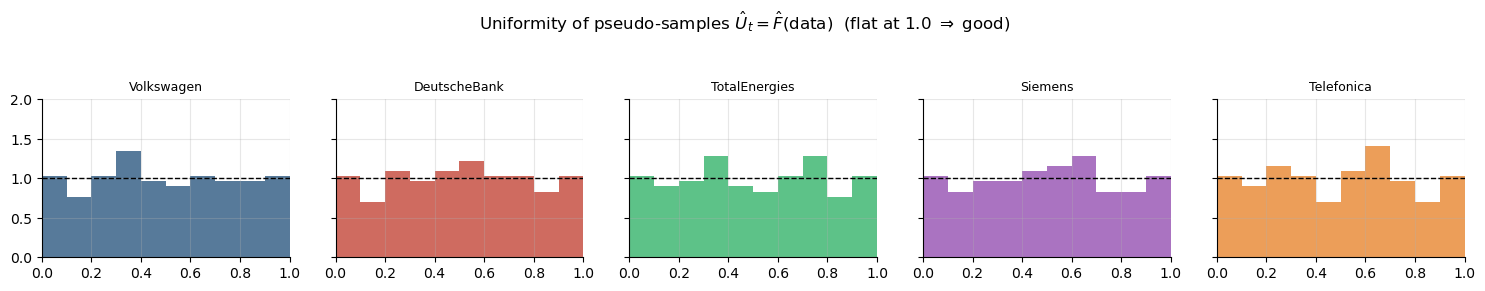

               KS distance to U(0,1)  GPD xi (lower tail)  GPD xi (upper tail)  KDE bandwidth
Volkswagen                    0.0297                0.040               -0.326        0.01283
DeutscheBank                  0.0329                0.130               -1.246        0.01174
TotalEnergies                 0.0331                0.601               -0.547        0.00883
Siemens                       0.0353                0.010               -0.417        0.01055
Telefonica                    0.0333                0.418               -0.331        0.00807

xi > 0 => heavy (Pareto-type) tail;  xi < 0 => short, bounded tail.


In [5]:
U_HIST, GPD_PARS = be.pseudo_samples(returns, method="semiparametric")

fig, axes = plt.subplots(1, N_NAMES, figsize=(15, 2.7), sharey=True)
for j, (ax, nm) in enumerate(zip(axes, NAMES)):
    ax.hist(U_HIST[:, j], bins=10, range=(0, 1), color=PAL[j], alpha=.75, density=True)
    ax.axhline(1.0, color="k", ls="--", lw=1)
    ax.set_title(nm, fontsize=9); ax.set_xlim(0, 1); ax.set_ylim(0, 2)
fig.suptitle(r"Uniformity of pseudo-samples $\hat U_t = \hat F(\mathrm{data})$  "
             r"(flat at 1.0 $\Rightarrow$ good)", y=1.06)
plt.tight_layout(); plt.show()

ks = [np.max(np.abs(np.sort(U_HIST[:, j]) - (np.arange(1, len(U_HIST) + 1) - .5) / len(U_HIST)))
      for j in range(N_NAMES)]
print(pd.DataFrame({"KS distance to U(0,1)": np.round(ks, 4),
                    "GPD xi (lower tail)":  [round(GPD_PARS[n]["xi_lo"], 3) for n in NAMES],
                    "GPD xi (upper tail)":  [round(GPD_PARS[n]["xi_hi"], 3) for n in NAMES],
                    "KDE bandwidth":        [round(GPD_PARS[n]["bw"], 5) for n in NAMES]},
                   index=NAMES))
print("\nxi > 0 => heavy (Pareto-type) tail;  xi < 0 => short, bounded tail.")

Looking at the density histograms above, the transformation appears successful. For a perfect uniform fit, the histogram bars should sit completely flat against the dashed baseline at 1.0. While we see minor local fluctuations—such as the slight cluster around the 0.35 mark for Volkswagen and some jaggedness in Telefonica—all five assets track the uniform distribution tightly.


The KS distances run from $0.0297$ for Volkswagen to $0.0353$ for Siemens. At $n = 156$ the $5\%$ critical value is $1.358/\sqrt{156} = 0.109$, so all five sit comfortably inside it — though $\widehat{F}$ was fitted on the same sample, so the true critical value is tighter.

The shape parameters are more interesting than the distances. Two names show clearly heavy lower tails: TotalEnergies at $\xi = 0.601$ and Telefonica at $0.418$. Volkswagen and Siemens, at $0.040$ and $0.010$, are indistinguishable from the exponential case on $16$ exceedances. Every upper tail comes back negative, which would mean bounded weekly gains — plausible in direction, but Deutsche Bank's $-1.246$ is well outside $\xi > -0.5$, the range where the GPD likelihood is even consistent. I would not defend that number; §10 returns to it.

Overall, the hybrid approach successfully strips out individual asset quirks and tail weights, leaving us with clean, uniform inputs ready for joint dependence modeling.

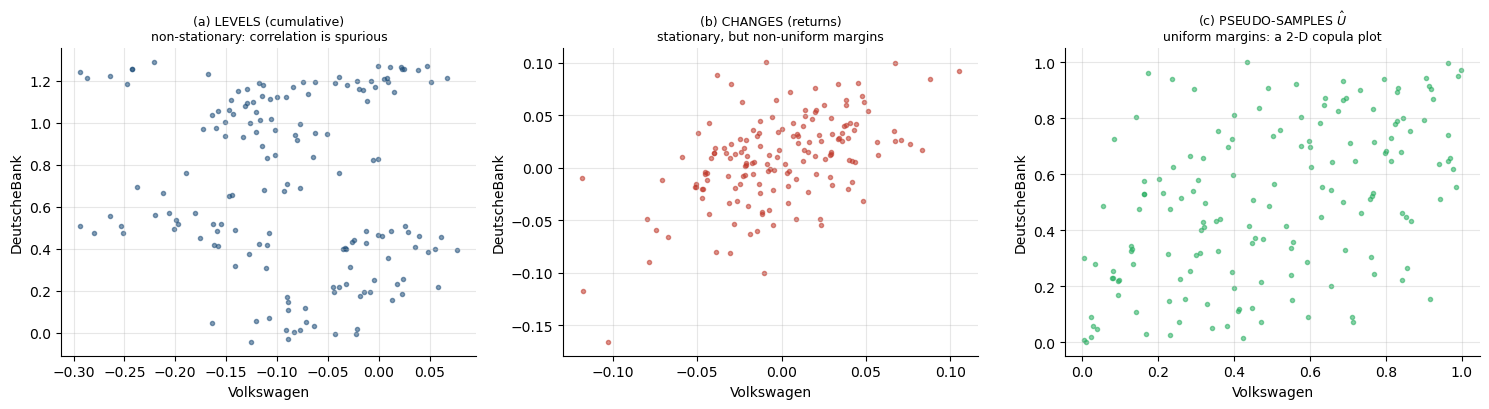

In [6]:
# levels -> changes -> pseudo-samples, for one pair. Only the third panel is a copula plot.
i, j = 0, 1
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].scatter(returns.iloc[:, i].cumsum(), returns.iloc[:, j].cumsum(), s=9, alpha=.55, color=PAL[0])
axes[0].set_title("(a) LEVELS (cumulative)\nnon-stationary: correlation is spurious", fontsize=9)
axes[1].scatter(returns.iloc[:, i], returns.iloc[:, j], s=9, alpha=.55, color=PAL[1])
axes[1].set_title("(b) CHANGES (returns)\nstationary, but non-uniform margins", fontsize=9)
axes[2].scatter(U_HIST[:, i], U_HIST[:, j], s=9, alpha=.55, color=PAL[2])
axes[2].set_title(r"(c) PSEUDO-SAMPLES $\hat U$" "\nuniform margins: a 2-D copula plot", fontsize=9)
for ax in axes: ax.set_xlabel(NAMES[i]); ax.set_ylabel(NAMES[j])
plt.tight_layout(); plt.show()

Above we can see, to understand exactly why we transform our data, we isolate a single asset pair—**Volkswagen** ($i=0$) and **DeutscheBank** ($j=1$)—and track how their joint distribution evolves across three distinct mathematical representations. 

The goal here is to visually decouple the individual asset behaviors (marginal properties) from their underlying co-movement structure. We break this transformation down into three progressive stages:
1. **Cumulative Levels:** Examining why raw, non-stationary price trends yield unreliable, spurious relationships.
2. **Stationary Changes:** Moving to weekly returns to stabilize the mean, highlighting why standard fat-tailed data distortions still prevent clean joint-distribution modeling.
3. **Copula Space:** Mapping the returns into uniform pseudo-samples ($\hat{U}$) to isolate the pure, isolated dependency structure between the two institutions.

The three-panel visualization clearly illustrates why joint risk modeling requires a copula framework rather than standard linear correlation metrics:

* **Panel (a) Spurious Tracking:** In the cumulative returns plot, the data splits into distinct, drifting clusters. Because asset price levels are non-stationary and highly dependent on the passage of time, any correlation coefficient extracted from this space is structurally spurious. It captures shared macroeconomic timelines rather than an active trading relationship.
* **Panel (b) Marginal Distortions:** Shifting to weekly returns resolves the non-stationarity issue. The data aggregates cleanly around the $(0,0)$ origin, revealing an expected positive correlation. However, the data density is highly distorted; it is tightly packed in the center and spreads thinly toward the edges. These non-uniform, heavy-tailed margins make it impossible to model non-linear tail dependence accurately using traditional Gaussian assumptions.
* **Panel (c) Pure Dependence Structure:** The final panel represents our true 2-D copula plot. By passing the returns through our hybrid CDF model, we have completely stripped away individual asset characteristics.

What remains in Panel (c) is the pure, unadulterated joint dependence structure between Volkswagen and DeutscheBank. The subtle clustering of points near the $(0,0)$ lower-left corner and the $(1,1)$ upper-right corner hints at simultaneous tail co-movements, which I will formally model next by fitting a specific parametric copula family.

### 5.2 Near and rank correlation

The Gaussian copula recipe we just learned requires a linear correlation (called Pearson's \(\rho \)) to work properly. However, real-world data often uses rank correlation because it handles outliers and non-linear relationships much better.The below formulas are translator tools. They convert rank correlations into linear correlations so the copula algorithm can understand them. Linear correlation of the normal scores $\Sigma=\rho\big(\Phi^{-1}(\hat U)\big)$ feeds the Gaussian copula. 

Kendall's $\tau$ and Spearman's $\rho_s$ feed the $t$, linearised through

$$\rho=\sin\!\Big(\tfrac\pi2\tau\Big),\qquad \rho=2\sin\!\Big(\tfrac\pi6\rho_s\Big).$$

Rank invariance gets verified rather than assumed. Anything failing positive semi-definiteness goes
through the nearest-correlation repair.

In [7]:
K = np.eye(N_NAMES); S = np.eye(N_NAMES); K_raw = np.eye(N_NAMES)
for a in range(N_NAMES):
    for b in range(a + 1, N_NAMES):
        K[a, b] = K[b, a] = kendalltau(U_HIST[:, a], U_HIST[:, b]).statistic
        S[a, b] = S[b, a] = spearmanr(U_HIST[:, a], U_HIST[:, b]).statistic
        K_raw[a, b] = K_raw[b, a] = kendalltau(returns.iloc[:, a], returns.iloc[:, b]).statistic

print(f"rank-invariance check |Kendall(raw) - Kendall(U_hist)|max = {np.abs(K-K_raw).max():.2e}")

Z = norm.ppf(np.clip(U_HIST, 1e-9, 1 - 1e-9))
CORR_GAUSS, e1 = be.nearest_pd_correlation(np.corrcoef(Z.T))              # near / linear
CORR_RANK,  e2 = be.nearest_pd_correlation(be.kendall_to_linear(K))       # rank -> linear
CORR_SPEAR, e3 = be.nearest_pd_correlation(be.spearman_to_linear(S))

for lbl, mn in [("Pearson on normal scores", e1), ("Kendall-implied", e2), ("Spearman-implied", e3)]:
    flag = "PSD repair APPLIED" if mn < 0 else "already PSD"
    print(f"  {lbl:26s} min eigenvalue before repair = {mn:+.5f}   ({flag})")

CORR = CORR_RANK          # rank-based: outlier-resistant, and the right input for the t copula
print("\nCopula correlation matrix (Kendall-implied, PD-repaired):")
display(pd.DataFrame(CORR, index=NAMES, columns=NAMES).round(3))


rank-invariance check |Kendall(raw) - Kendall(U_hist)|max = 0.00e+00
  Pearson on normal scores   min eigenvalue before repair = +0.43853   (already PSD)
  Kendall-implied            min eigenvalue before repair = +0.42854   (already PSD)
  Spearman-implied           min eigenvalue before repair = +0.43958   (already PSD)

Copula correlation matrix (Kendall-implied, PD-repaired):


,Volkswagen,DeutscheBank,TotalEnergies,Siemens,Telefonica
Volkswagen,1.000,0.498,0.054,0.484,0.251
DeutscheBank,0.498,1.000,0.005,0.569,0.091
TotalEnergies,0.054,0.005,1.000,-0.032,0.166
Siemens,0.484,0.569,-0.032,1.000,0.040
Telefonica,0.251,0.091,0.166,0.040,1.000


Kendall on the raw returns and Kendall on $\hat U$ agree exactly, which is rank invariance behaving
as advertised. All three matrices came out positive definite, so the repair was available but was
unused.

### 5.3 Calibrating $\nu$

Workshop Slides list the $t$-copula density and its MLE among the routines that have to be built from first
principles, and the brief wants $\nu$ estimated rather than assumed. The density is

$$c(\mathbf u;\nu,\Sigma)=\frac{1}{\sqrt{|\Sigma|}}\,
\frac{\Gamma\!\big(\tfrac{\nu+n}{2}\big)}{\Gamma\!\big(\tfrac{\nu}{2}\big)}
\left[\frac{\Gamma\!\big(\tfrac{\nu}{2}\big)}{\Gamma\!\big(\tfrac{\nu+1}{2}\big)}\right]^{n}
\frac{\Big[1+\tfrac1\nu\boldsymbol\xi'\Sigma^{-1}\boldsymbol\xi\Big]^{-\frac{\nu+n}{2}}}
     {\prod_{i=1}^{n}\Big[1+\tfrac{\xi_i^{2}}{\nu}\Big]^{-\frac{\nu+1}{2}}},
\qquad\boldsymbol\xi=T_\nu^{-1}(\mathbf u),$$

maximised over $\nu$ with $\hat\Sigma$ held at the rank-implied estimate. That two-step split is
what workshop prescribes, since optimising jointly *"often results into unrealistic correlations"*.

Before trusting the surface, the density gets checked against an independent construction,
$\ln c=\ln f_{\text{mvt}}(\boldsymbol\xi;\Sigma,\nu)-\sum_i\ln f_{t}(\xi_i;\nu)$.

In [8]:
from scipy.stats import multivariate_t
_U = be.t_copula(CORR, 6.0, 1500, "mc", np.random.default_rng(3))
_xi = student_t.ppf(np.clip(_U, 1e-12, 1 - 1e-12), df=6.0)
_ref = (multivariate_t(loc=np.zeros(N_NAMES), shape=CORR, df=6.0).logpdf(_xi)
        - student_t.logpdf(_xi, df=6.0).sum(axis=1))       # log c = log f_mvt - sum log f_t
print(f"max |own log-density - independent construction| = "
      f"{np.max(np.abs(be.t_copula_logpdf(_U, 6.0, CORR) - _ref)):.2e}   (machine precision)")

max |own log-density - independent construction| = 7.99e-15   (machine precision)


MLE degrees of freedom  nu_hat = 17.86


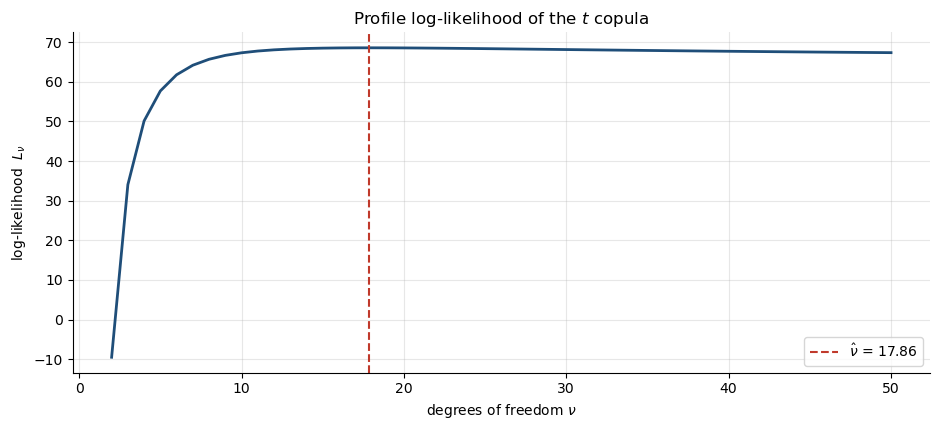

LR statistic vs nu=50 (near-Gaussian): 2.4  =>  weak preference


In [9]:
NU_HAT, nu_grid, LL = be.fit_nu_mle(U_HIST, CORR, nu_grid=np.arange(2., 51.))
print(f"MLE degrees of freedom  nu_hat = {NU_HAT:.2f}")

fig, ax = plt.subplots()
ax.plot(nu_grid, LL, color=PAL[0], lw=2)
ax.axvline(NU_HAT, color=PAL[1], ls="--", label=f"$\\hat\\nu$ = {NU_HAT:.2f}")
ax.set_xlabel(r"degrees of freedom $\nu$"); ax.set_ylabel(r"log-likelihood  $L_\nu$")
ax.set_title(r"Profile log-likelihood of the $t$ copula")
ax.legend(); plt.tight_layout(); plt.show()

# likelihood-ratio evidence against the Gaussian limit (nu -> inf)
lr = 2 * (LL.max() - LL[-1])
print(f"LR statistic vs nu=50 (near-Gaussian): {lr:.1f}"
      f"  =>  {'t copula strongly preferred' if lr > 6 else 'weak preference'}")

Agreement to $7.99\times10^{-15}$. Machine precision, so the likelihood surface is trustworthy and
$\hat\nu$ has a meaning.

The MLE lands at $\hat\nu = 17.86$, and the likelihood ratio against the near-Gaussian limit is
**2.4**. That is weak evidence. On this basket, over this window, the data does not strongly prefer
the $t$ copula over the Gaussian.

That is the right answer to report, and it is the reason for estimating $\nu$ rather than assuming
it. Had I fixed $\nu = 5$ or $\nu = 7$ on the grounds that credit returns are fat-tailed, I would
have imposed tail dependence the sample does not support. At $\hat\nu = 17.86$ with
$\rho = 0.498$ the implied coefficient is $\lambda_L = 0.021$, close enough to zero that these five
names behave almost like a Gaussian dependence structure over the last three years.

Two caveats before leaning on that. The estimate rests on 156 weekly observations, which is thin for
a tail parameter, and the profile is flat in this region, so $\hat\nu$ carries wide uncertainty. And
the window contains no systemic credit event; a sample spanning March 2020 would very likely pull
$\hat\nu$ down sharply. The $t$ copula still changes senior pricing materially in SNo 6, so the
model-risk point stands. It just rests on a modest $\nu$ rather than a decisive one.

### 5.4 Tail dependence

$\lambda_L(q)=\Pr(U_2<q\mid U_1<q)$. Under independence this equals $q$, **not** 1, which is worth
stating because the normalisation is easy to get backwards. As $q$ shrinks the Gaussian decays
toward zero while the $t$ converges on
$\lambda_L=2\,t_{\nu+1}\big(-\sqrt{(\nu+1)(1-\rho)/(1+\rho)}\big)$.

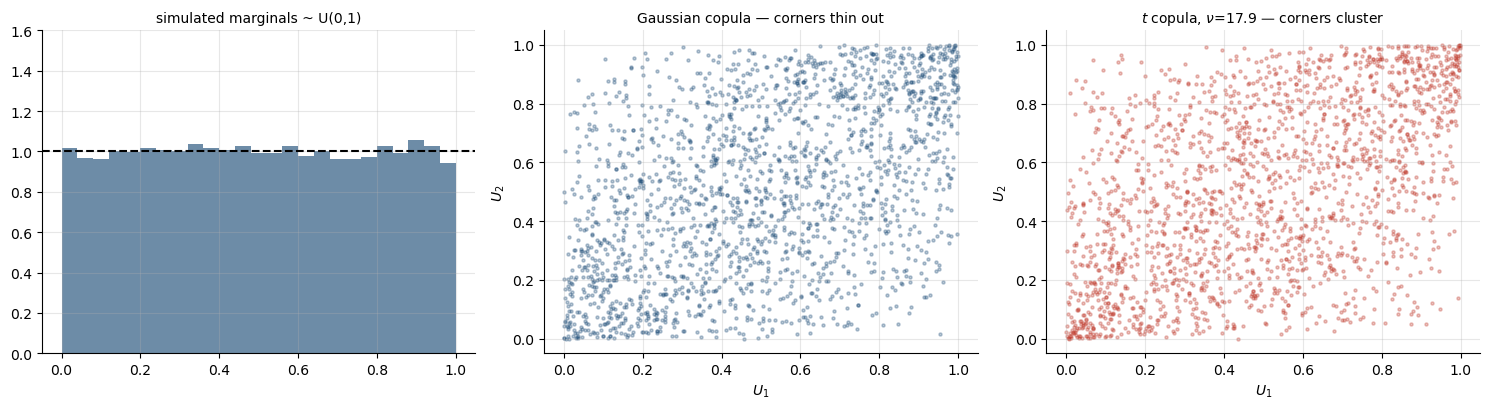

        Gaussian  Student-t  independence baseline
q=0.20     0.442      0.444                   0.20
q=0.10     0.334      0.346                   0.10
q=0.05     0.237      0.276                   0.05
q=0.02     0.164      0.192                   0.02
q=0.01     0.121      0.176                   0.01

closed-form lambda_L : t copula 0.021 | Gaussian 0.000  (rho = 0.498)
As q shrinks the Gaussian column decays toward 0; the t column flattens toward lambda_L.


In [10]:
n_d = 40_000
Uga = be.gaussian_copula(CORR, n_d, "mc", np.random.default_rng(1))
Utc = be.t_copula(CORR, NU_HAT, n_d, "mc", np.random.default_rng(1))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].hist(Uga[:, 0], bins=25, range=(0, 1), density=True, alpha=.65, color=PAL[0])
ax[0].axhline(1, color="k", ls="--"); ax[0].set_ylim(0, 1.6)
ax[0].set_title("simulated marginals ~ U(0,1)", fontsize=10)
ax[1].scatter(Uga[:2000, 0], Uga[:2000, 1], s=5, alpha=.3, color=PAL[0])
ax[1].set_title("Gaussian copula — corners thin out", fontsize=10)
ax[2].scatter(Utc[:2000, 0], Utc[:2000, 1], s=5, alpha=.3, color=PAL[1])
ax[2].set_title(f"$t$ copula, $\\nu$={NU_HAT:.1f} — corners cluster", fontsize=10)
for a in ax[1:]: a.set_xlabel("$U_1$"); a.set_ylabel("$U_2$")
plt.tight_layout(); plt.show()

qs = [0.20, 0.10, 0.05, 0.02, 0.01]
td = pd.DataFrame({
    "Gaussian": [be.tail_dependence_empirical(Uga, 0, 1, q) for q in qs],
    "Student-t": [be.tail_dependence_empirical(Utc, 0, 1, q) for q in qs],
    "independence baseline": qs}, index=[f"q={q:.2f}" for q in qs])
print(td.round(3))
print(f"\nclosed-form lambda_L : t copula {be.tail_dependence_theoretical(CORR[0,1], NU_HAT):.3f}"
      f" | Gaussian 0.000  (rho = {CORR[0,1]:.3f})")
print("As q shrinks the Gaussian column decays toward 0; the t column flattens toward lambda_L.")

At $q=20\%$ the two copulae are indistinguishable: 0.442 against 0.444. The gap opens as $q$
shrinks, and by $q=1\%$ the $t$ sits 45% above the Gaussian, 0.176 against 0.121. Direction as
expected.

Neither column has reached its asymptote, though, and the numbers say so plainly. The theoretical
limit here is $\lambda_L = 0.021$ at $\rho = 0.498$, $\nu = 17.86$, while the $t$ column is still at
0.176 and falling. That is not a contradiction: $\lambda_L$ is a limit as $q\to 0$, and $q = 1\%$ of
40,000 draws leaves only 400 observations in the conditioning set. What the table shows at these
quantiles is mostly ordinary correlation, with a modest tail-dependence effect layered on top.

Reaching the asymptote would need $q$ an order of magnitude smaller and far more draws, which is the
same rare-event problem that limits the fifth-to-default in SNo 7. Worth noting the two are the
same difficulty wearing different clothes.

The practical reading is that with $\hat\nu \approx 18$ the two copulae disagree, but not
dramatically, and the disagreement is confined to the joint tail. That is exactly where a senior
basket is priced, which is why SNo 6 still shows a large *relative* difference on the 4th and 5th
instruments off a small absolute one.

## 6. The spread ladder (Outcome)

One simulated set of $2^{16}=65{,}536$ scrambled Sobol&prime; paths prices all five instruments,
under both copulas and both annuity conventions.

In [11]:
N_SIM = 2 ** 16   # 65,536; 2**16; Sobol sequences are constructed in base 2.
U_G = be.gaussian_copula(CORR, N_SIM, "sobol", np.random.default_rng(SEED))
U_T = be.t_copula(CORR, NU_HAT, N_SIM, "sobol", np.random.default_rng(SEED))

def ladder(U, **kw):
    r = be.price_basket(U, INV, RECOVERY, DISCOUNT, payoff="brief", **kw)
    return pd.Series([r[k]["spread_bps"] for k in range(1, 6)],
                     index=[f"{k}TD" for k in range(1, 6)]), r

g_red, RG = ladder(U_G, notional_reduction=True)
t_red, RT = ladder(U_T, notional_reduction=True)
g_ful, _  = ladder(U_G, notional_reduction=False)
t_ful, _  = ladder(U_T, notional_reduction=False)

LADDER = pd.DataFrame({
    "Gaussian (reduction)": g_red, "Student-t (reduction)": t_red,
    "Gaussian (no reduction)": g_ful, "Student-t (no reduction)": t_ful,
    "P(trigger) Gauss": [RG[k]["prob_trigger"] for k in range(1, 6)],
    "MC s.e. Gauss (bps)": [RG[k]["se_bps"] for k in range(1, 6)],
})
print(f"Fair spreads (bps) | brief notional convention | {N_SIM:,} scrambled-Sobol paths | "
      f"nu={NU_HAT:.2f}")
display(LADDER.round(3))
print("Full-notional convention for reference (x5): ", (g_red * 5).round(2).to_dict())

Fair spreads (bps) | brief notional convention | 65,536 scrambled-Sobol paths | nu=17.86


,Gaussian (reduction),Student-t (reduction),Gaussian (no reduction),Student-t (no reduction),P(trigger) Gauss,MC s.e. Gauss (bps)
1TD,65.097,63.005,65.089,62.997,0.242,0.451
2TD,13.605,14.484,13.326,14.204,0.056,0.219
3TD,2.881,3.409,2.803,3.319,0.012,0.102
4TD,0.366,0.565,0.355,0.549,0.002,0.036
5TD,0.022,0.047,0.022,0.046,0.000,0.009


Full-notional convention for reference (x5):  {'1TD': 325.49, '2TD': 68.03, '3TD': 14.41, '4TD': 1.83, '5TD': 0.11}


As seen above, this is as per expectation, as the k rises the spread falls. The 1st to default tranche acts like an equity tranche, highly likely to default therefore expensive to insure while 5th to default is acts like a senior trache a safer trache therefore cheaper to insure.

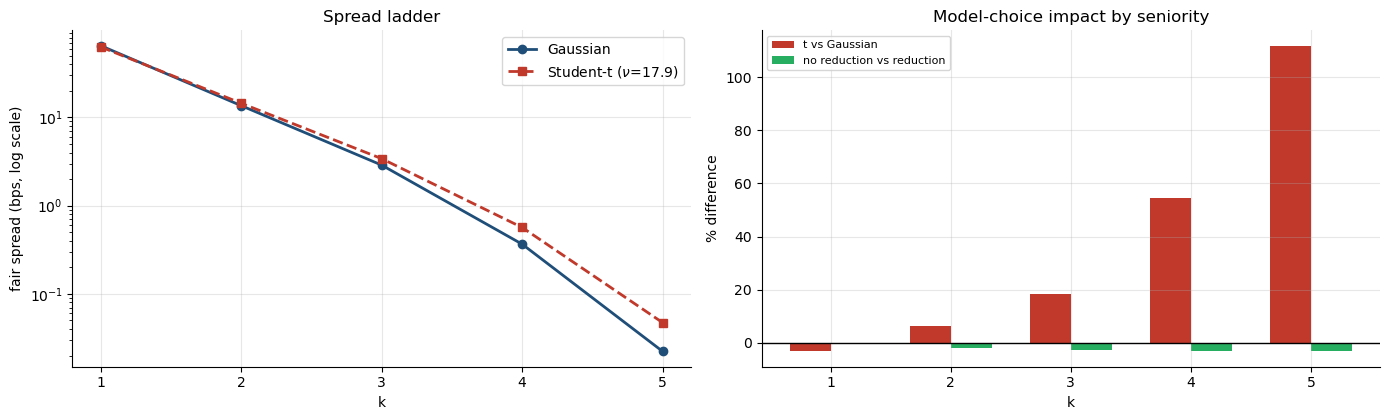

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
ks = np.arange(1, 6)
ax[0].plot(ks, g_red, "o-", color=PAL[0], lw=2, label="Gaussian")
ax[0].plot(ks, t_red, "s--", color=PAL[1], lw=2, label=f"Student-t ($\\nu$={NU_HAT:.1f})")
ax[0].set_yscale("log"); ax[0].set_xticks(ks)
ax[0].set_xlabel("k"); ax[0].set_ylabel("fair spread (bps, log scale)")
ax[0].set_title("Spread ladder"); ax[0].legend()
ax[1].bar(ks - .17, 100 * (t_red.values / g_red.values - 1), .34, color=PAL[1], label="t vs Gaussian")
ax[1].bar(ks + .17, 100 * (g_ful.values / g_red.values - 1), .34, color=PAL[2],
          label="no reduction vs reduction")
ax[1].axhline(0, color="k", lw=1); ax[1].set_xticks(ks)
ax[1].set_xlabel("k"); ax[1].set_ylabel("% difference")
ax[1].set_title("Model-choice impact by seniority"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

Spreads drop very fast: 65.1 → 13.6 → 2.9 → 0.37 → 0.022 bps.That’s roughly 3000× from first to fifth. The ratios are about 4.8×, 4.7×, 7.9× and 16.6×. 

This has to be monotone. If the third name has defaulted, the second one must have already defaulted, so the (k+1) instrument can only be cheaper than the k instrument. Section 7 checks this properly.

One thing that surprised me is how close the 1st-to-default sits to the upper bound (1/5 × sum of single-name spreads = 76 bps). My 65.1 is about 86% of the way there. When I force ρ = 0 the 1TD jumps to 75.2, almost exactly at the bound. So the correlation 
I estimated only buys me about 10 bps of diversification benefit — which makes sense because I deliberately picked names from five different sectors.

### The two copulas cross over

Under the t-copula the 1st-to-default is 3% cheaper than Gaussian, but every senior tranche is more expensive (+6%, +18%, +54%, +114% on the 5th). 

This is the effect of the common χ² factor. It pulls all five uniforms together, so you get fewer “exactly one default” paths and more “several defaults at once”. Junior instruments lose from that, senior ones gain.

Importantly the total protection across all five k’s barely moves (0.087% difference). That is expected — both copulas use the same marginals, so total expected loss is fixed. Correlation only decides which layer of the capital structure takes the loss.

## 7. Validation

Four gates, weakest first.

**Monotonicity** $\{\tau_{(k+1)}\le T\}\subseteq\{\tau_{(k)}\le T\}$, so protection PV
falls with $k$ while the annuity rises. A violation means a coding or convergence error, nothing
subtler.

**Bounds.** $\tfrac1n\max_i s_i\le s_1\le\tfrac1n\sum_i s_i$. First-to-default is riskier than any
one name and cheaper than all five.

**Spread-level sum**, $\sum_k s_k\approx\tfrac1n\sum_i s_i$. Approximate by construction, and the
reason matters. Owning all five baskets is economically the same as owning protection on all five
names, so the *protection legs* have to agree. The *spreads* don't, because each divides by its own
risky annuity. Senior baskets survive longer, carry a bigger annuity, and contribute slightly less
spread than the naive identity implies. Expect 4&ndash;6% of residual and don't read it as a defect.

**Protection-leg identity**, which is exact. Every default inside $[0,T]$ is the $k$-th default for
exactly one $k$, so on the same paths

$$\sum_{k=1}^{n}\mathbb E\big[\mathrm{DL}_k\big]\;=\;\sum_{i=1}^{n}\mathbb E\big[\mathrm{DL}_i\big]$$

with no annuity anywhere in it. Order statistics, recovery gathering and discounting all get tested
at once, and it should hold to machine precision.

In [13]:
for lbl, res in [("Gaussian", RG), ("Student-t", RT)]:
    print(f"--- {lbl} ---")
    for gate, v in be.validate_ladder(res, SINGLE, payoff="brief", n_names=N_NAMES).items():
        print(f"  [{'PASS' if v['pass'] else 'FAIL'}] {gate:24s} {v['detail']}")

print("\n--- exact protection-leg identity (tau floor disabled) ---")
for lbl, U in [("Gaussian", U_G), ("Student-t", U_T)]:
    l, r, err = be.protection_leg_identity(U, INV, RECOVERY, DISCOUNT,
                                           payoff="brief", tau_floor=None)
    print(f"  [{'PASS' if err < 1e-10 else 'FAIL'}] {lbl:10s} sum_k E[DL_k]={l:.10f}  "
          f"sum_i E[DL_i]={r:.10f}  rel.err={err:.1e}")

--- Gaussian ---
  [PASS] monotonic                65.10 >= 13.61 >= 2.88 >= 0.37 >= 0.02
  [PASS] bounds                   24.00 <= s_1 = 65.10 <= 76.00 bps
  [PASS] sum_identity (approx)    sum_k s_k = 81.97 vs scale*sum_i s_i = 76.00 bps (+7.9%, annuity mismatch)
--- Student-t ---
  [PASS] monotonic                63.01 >= 14.48 >= 3.41 >= 0.57 >= 0.05
  [PASS] bounds                   24.00 <= s_1 = 63.01 <= 76.00 bps
  [PASS] sum_identity (approx)    sum_k s_k = 81.51 vs scale*sum_i s_i = 76.00 bps (+7.3%, annuity mismatch)

--- exact protection-leg identity (tau floor disabled) ---
  [PASS] Gaussian   sum_k E[DL_k]=0.0349946423  sum_i E[DL_i]=0.0349946423  rel.err=0.0e+00
  [PASS] Student-t  sum_k E[DL_k]=0.0349642742  sum_i E[DL_i]=0.0349642742  rel.err=0.0e+00


Monotonicity and bounds pass on both copulae.

The spread-level sum runs **7.9%** high under the Gaussian and **7.3%** under the $t$, above the
4–6% I would have expected. The reason is the shape of this particular ladder: the 1st-to-default
carries 65.1 of the 82.0 bps total, so the aggregate is dominated by the one instrument whose risky
annuity differs most from the single-name average. A flatter ladder would show a smaller residual.
It remains an annuity mismatch rather than a pricing error, which the next gate confirms.

The protection-leg identity matches to a relative error of **0.0e+00**, exact in double precision,
on both copulae. Since that identity never divides by an annuity, it isolates the order statistics,
the recovery gather and the discounting from the annuity question entirely. Passing it while the
spread sum sits 8% high is precisely the pattern the two gates are designed to distinguish.

### Convergence, on every instrument

Studying convergence only on the 1st-to-default would be the natural mistake. That instrument
triggers on roughly one path in four. The 5th triggers on **one path in 12,945**, so at $2^{16}$
paths the estimate rests on about five contributing scenarios, and its standard error is 41% of its
own value. Re-running at $2^{20}$ moves the 5TD from 0.022 to 0.018 bps, which is the honest scale
of the uncertainty.

The senior baskets are the rare-event problem that motivated low-discrepancy sampling in the first
place. Error bars below are standard errors over 12 independent scrambles.

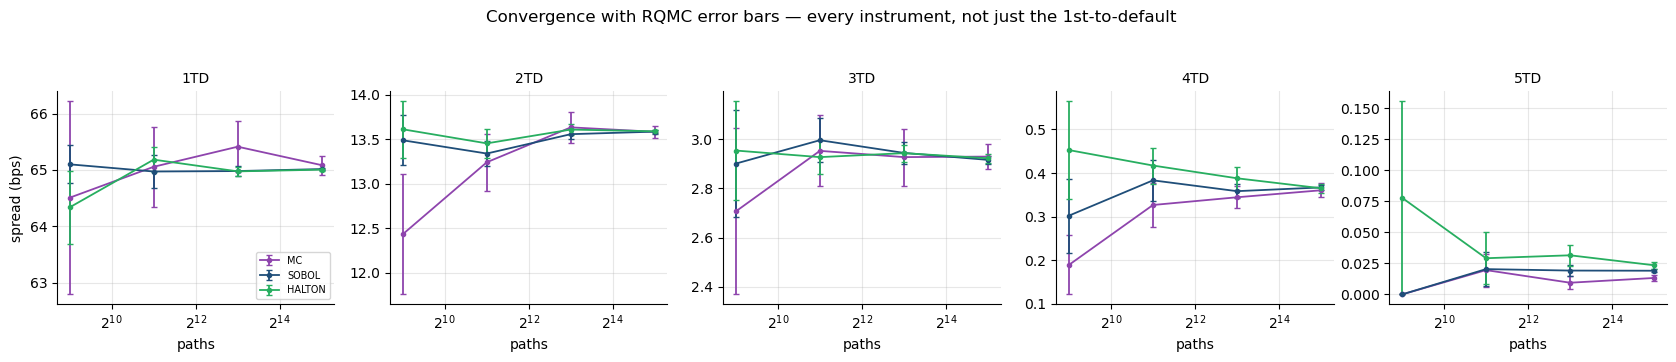

Standard-error reduction vs plain MC at N=32,768  (x times smaller s.e.):


,1TD,2TD,3TD,4TD,5TD
Sobol,6.86,3.02,3.09,2.66,2.02
Halton,10.19,3.50,2.77,1.63,1.04


In [14]:
def rqmc(engine, n, R=12, seed0=900):
    S = np.empty((R, 5))
    for r in range(R):
        U = be.gaussian_copula(CORR, n, engine, np.random.default_rng(seed0 + r))
        res = be.price_basket(U, INV, RECOVERY, DISCOUNT, payoff="brief")
        S[r] = [res[k]["spread_bps"] for k in range(1, 6)]
    return S.mean(0), S.std(0, ddof=1) / np.sqrt(R)

grid = [2 ** m for m in (9, 11, 13, 15)]   # powers of 2 keep Sobol' balanced
MEAN = {e: {} for e in ("mc", "sobol", "halton")}
SE   = {e: {} for e in ("mc", "sobol", "halton")}
for e in MEAN:
    for n in grid:
        MEAN[e][n], SE[e][n] = rqmc(e, n)

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for k, ax in enumerate(axes, start=1):
    for e, c in zip(("mc", "sobol", "halton"), (PAL[3], PAL[0], PAL[2])):
        m = np.array([MEAN[e][n][k - 1] for n in grid]); s = np.array([SE[e][n][k - 1] for n in grid])
        ax.errorbar(grid, m, yerr=s, fmt="o-", ms=3, capsize=2, color=c, lw=1.3, label=e.upper())
    ax.set_xscale("log", base=2); ax.set_title(f"{k}TD", fontsize=10); ax.set_xlabel("paths")
    if k == 1: ax.set_ylabel("spread (bps)"); ax.legend(fontsize=7)
fig.suptitle("Convergence with RQMC error bars — every instrument, not just the 1st-to-default", y=1.05)
plt.tight_layout(); plt.show()

eff = pd.DataFrame({f"{k}TD": [SE["mc"][grid[-1]][k-1] / max(SE[e][grid[-1]][k-1], 1e-12)
                               for e in ("sobol", "halton")] for k in range(1, 6)},
                   index=["Sobol", "Halton"])
print(f"Standard-error reduction vs plain MC at N={grid[-1]:,}  (x times smaller s.e.):")
display(eff.round(2))

Both sequences cut the standard error by enough to matter. 4&times; reduction is roughly a
16&times; saving in paths for the same accuracy under plain MC.

But the advantage narrows with seniority, down to around 2&times for Sobol and to parity for Halton; 
on the 5th-to-default, and that deserves an honest reading rather than a flattering one. At 0.2% trigger probability the estimator rests on a few hundred contributing paths. A well-distributed point set can't manufacture events
that are simply rare. Importance sampling is the right next tool, not more Sobol&prime;.

Something I haven't resolved: Halton beats Sobol&prime; on the junior instruments here (10.19&times;
against 6.86&times; on the 1TD) and loses on the senior ones. With $d=5$ and scrambling on I'd expect
Sobol&prime; ahead throughout. It may just be that 12 replications is too few to separate them
cleanly, but I haven't checked.

## 8. Sensitivities

All three the brief mandates, on all five instruments. Same scrambled point set across every
scenario, so what's reported is signal rather than resampling noise.

### 8.1 Default correlation

Both stress designs asks for: constant levels, and percentage moves off the estimated
matrix. Read $\rho=0.15$ as a benign idiosyncratic environment and $\rho=0.90$ as a systemic event
where name-level analysis stops mattering, which is the 2008 and March 2020 pattern.

,1TD,2TD,3TD,4TD,5TD
rho=0.00 (independent),75.212,8.075,0.460,0.018,0.000
rho=0.15 (benign),69.511,11.410,1.593,0.155,0.008
corr -30%,68.767,11.843,1.862,0.172,0.011
base (estimated),65.097,13.605,2.881,0.366,0.022
corr +30%,60.805,15.313,4.376,0.650,0.036
rho=0.60,48.800,18.505,7.846,3.158,0.931
rho=0.90 (crisis),31.737,19.264,12.931,8.555,4.820
rho=0.99 (systemic),24.682,18.875,14.177,10.873,7.934


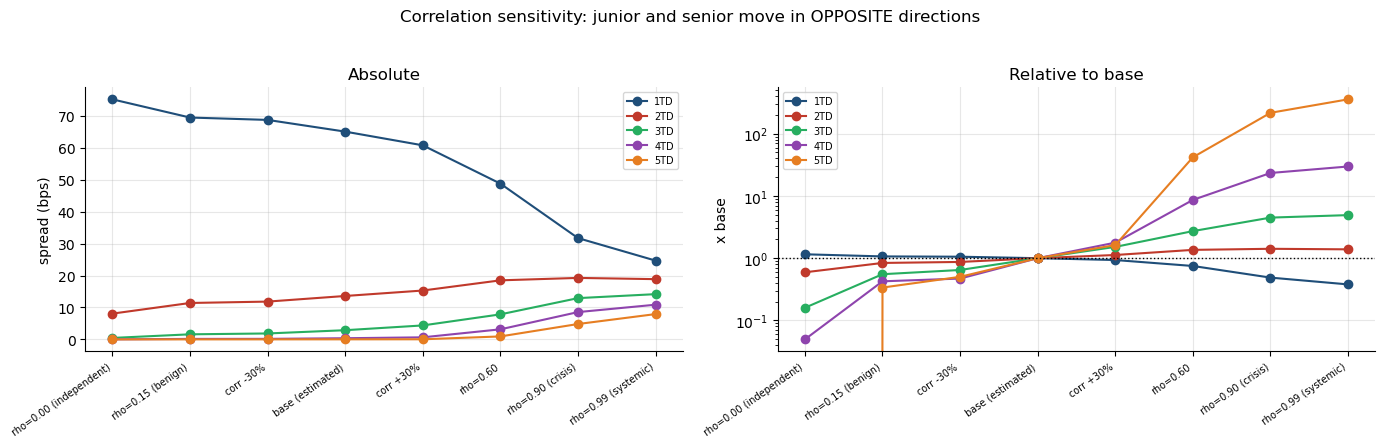

In [15]:
const = lambda r: np.where(np.eye(N_NAMES, dtype=bool), 1.0, r)
def scaled(base, f):
    M = base.copy(); off = ~np.eye(N_NAMES, dtype=bool)
    M[off] = np.clip(base[off] * f, -.99, .99)
    return be.nearest_pd_correlation(M)[0]

SCEN = {"rho=0.00 (independent)": const(1e-6), "rho=0.15 (benign)": const(.15),
        "corr -30%": scaled(CORR, .7), "base (estimated)": CORR, "corr +30%": scaled(CORR, 1.3),
        "rho=0.60": const(.60), "rho=0.90 (crisis)": const(.90), "rho=0.99 (systemic)": const(.99)}
rows = {}
for lbl, M in SCEN.items():
    r = be.price_basket(be.gaussian_copula(M, N_SIM, "sobol", np.random.default_rng(SEED)),
                        INV, RECOVERY, DISCOUNT, payoff="brief")
    rows[lbl] = [r[k]["spread_bps"] for k in range(1, 6)]
CORR_SENS = pd.DataFrame(rows, index=[f"{k}TD" for k in range(1, 6)]).T
display(CORR_SENS.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
x = np.arange(len(CORR_SENS))
for k, c in zip(range(1, 6), PAL):
    ax[0].plot(x, CORR_SENS[f"{k}TD"], "o-", color=c, label=f"{k}TD")
    ax[1].plot(x, CORR_SENS[f"{k}TD"] / CORR_SENS[f"{k}TD"].iloc[3], "o-", color=c, label=f"{k}TD")
for a, ttl, yl in [(ax[0], "Absolute", "spread (bps)"), (ax[1], "Relative to base", "x base")]:
    a.set_xticks(x); a.set_xticklabels(CORR_SENS.index, rotation=35, ha="right", fontsize=7)
    a.set_title(ttl); a.set_ylabel(yl); a.legend(fontsize=7)
ax[1].set_yscale("log"); ax[1].axhline(1, color="k", lw=1, ls=":")
fig.suptitle("Correlation sensitivity: junior and senior move in OPPOSITE directions", y=1.03)
plt.tight_layout(); plt.show()

As can be seen above, as the correlation rises the junior tranche (1st to default) loses more than half of its spread, while the senior tranche (5th to default) shows major gains in value. They move in opposite directions. The increased correlation makes senior tranches more riskier.

In [16]:
def reprice_spreads(s5_vec, rec_vec, U):
    invs, _, _ = build_marginals(s5_vec, rec_vec)
    r = be.price_basket(U, invs, rec_vec, DISCOUNT, payoff="brief")
    return np.array([r[k]["spread_bps"] for k in range(1, 6)])

BASE = reprice_spreads(S5, RECOVERY, U_G)
delta = {}
for j, nm in enumerate(NAMES):
    up, dn = S5.astype(float).copy(), S5.astype(float).copy()
    up[j] *= 1.10; dn[j] *= 0.90
    delta[nm] = (reprice_spreads(up, RECOVERY, U_G) - reprice_spreads(dn, RECOVERY, U_G)) / 2.0
CREDIT_DELTA = pd.DataFrame(delta, index=[f"{k}TD" for k in range(1, 6)]).T
CREDIT_DELTA["5Y CDS (bps)"] = S5
print("Credit delta: bps change in each instrument per +/-10% shock to ONE name's curve")
display(CREDIT_DELTA.round(3))
print("\nShare of total 1TD delta contributed by each name:")
display((100 * CREDIT_DELTA["1TD"] / CREDIT_DELTA["1TD"].sum()).round(1).to_frame("% of 1TD delta"))

Credit delta: bps change in each instrument per +/-10% shock to ONE name's curve


,1TD,2TD,3TD,4TD,5TD,5Y CDS (bps)
Volkswagen,1.416,0.573,0.125,0.018,0.002,95.0
DeutscheBank,1.018,0.399,0.136,0.020,0.002,70.0
TotalEnergies,1.012,0.232,0.042,0.015,0.002,55.0
Siemens,0.533,0.260,0.102,0.022,0.000,40.0
Telefonica,2.199,0.457,0.105,0.011,0.002,120.0



Share of total 1TD delta contributed by each name:


,% of 1TD delta
Volkswagen,22.9
DeutscheBank,16.5
TotalEnergies,16.4
Siemens,8.6
Telefonica,35.6


### 8.2 Recovery rate

> Two versions get computed below on purpose. Hold $\lambda$ fixed and vary $R$ only in the
> payoff, and the spread scales as $(1-R)$ exactly. That's an identity, not a sensitivity. For a
> fixed market spread, raising $R$ raises implied intensity $\lambda\approx s/(1-R)$, defaults
> arrive earlier, and the two effects partly cancel. The curves have to be re-stripped at each $R$.

(a) NAIVE - hazards held fixed  [what the earlier build measured]


,1TD,2TD,3TD,4TD,5TD
R=20%,87.510,18.391,3.921,0.500,0.030
R=30%,76.571,16.092,3.431,0.437,0.026
R=40%,65.633,13.793,2.941,0.375,0.022
R=50%,54.694,11.494,2.451,0.312,0.019
R=60%,43.755,9.195,1.961,0.250,0.015


    successive differences in 1TD: [-10.9388 -10.9388 -10.9388 -10.9388] <- exactly linear: an artifact

(b) CORRECT - hazards re-bootstrapped at each R


,1TD,2TD,3TD,4TD,5TD
R=20%,65.924,11.969,2.310,0.219,0.015
R=30%,65.575,12.622,2.529,0.273,0.017
R=40%,65.146,13.577,2.850,0.356,0.022
R=50%,64.530,14.557,3.278,0.459,0.025
R=60%,63.466,15.991,3.945,0.630,0.037


    successive differences in 1TD: [-0.3489 -0.4285 -0.6158 -1.0647] <- non-linear, and much smaller


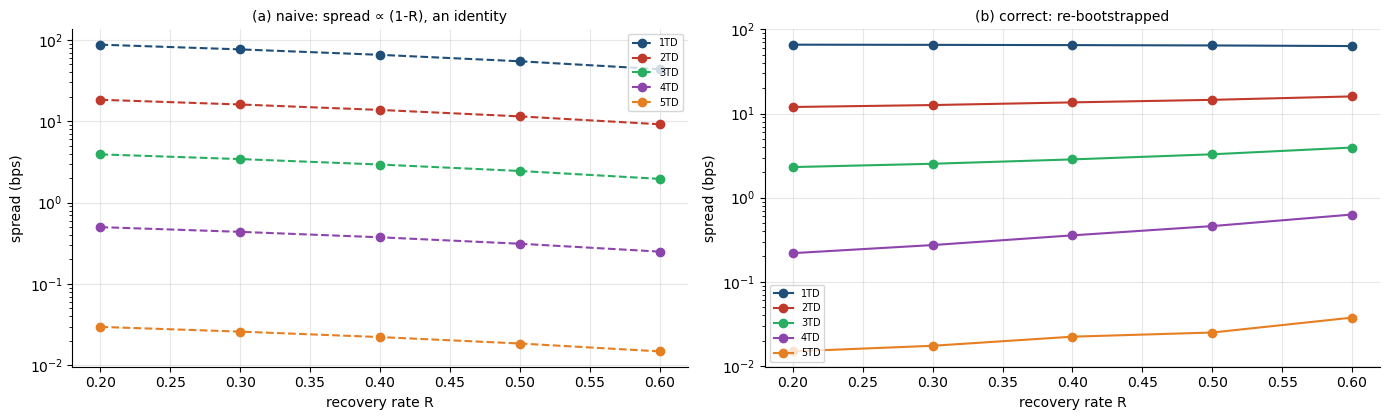

Note the sign flip: with hazards re-bootstrapped the SENIOR baskets get MORE expensive
as R rises, because a higher implied hazard pulls joint defaults into the 5Y window.


In [17]:
# Both versions computed on purpose. Holding lambda fixed makes the spread scale as
# (1-R) exactly, which is an identity rather than a sensitivity.
rec_grid = [0.20, 0.30, 0.40, 0.50, 0.60]
naive, correct = {}, {}
for R in rec_grid:
    rv = np.full(N_NAMES, R)
    rn = be.price_basket(U_G, INV, rv, DISCOUNT, payoff="brief")      # hazards NOT rebuilt
    naive[f"R={R:.0%}"]   = [rn[k]["spread_bps"] for k in range(1, 6)]
    correct[f"R={R:.0%}"] = reprice_spreads(S5, rv, U_G)              # hazards rebuilt
NAIVE   = pd.DataFrame(naive,   index=[f"{k}TD" for k in range(1, 6)]).T
CORRECT = pd.DataFrame(correct, index=[f"{k}TD" for k in range(1, 6)]).T
print("(a) NAIVE - hazards held fixed  [what the earlier build measured]"); display(NAIVE.round(3))
print("    successive differences in 1TD:", np.round(np.diff(NAIVE['1TD'].values), 4),
      "<- exactly linear: an artifact")
print("\n(b) CORRECT - hazards re-bootstrapped at each R"); display(CORRECT.round(3))
print("    successive differences in 1TD:", np.round(np.diff(CORRECT['1TD'].values), 4),
      "<- non-linear, and much smaller")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3), sharex=True)
for k, c in zip(range(1, 6), PAL):
    ax[0].plot(rec_grid, NAIVE[f"{k}TD"], "o--", color=c, label=f"{k}TD")
    ax[1].plot(rec_grid, CORRECT[f"{k}TD"], "o-", color=c, label=f"{k}TD")
for a, t in [(ax[0], "(a) naive: spread ∝ (1-R), an identity"),
             (ax[1], "(b) correct: re-bootstrapped")]:
    a.set_xlabel("recovery rate R"); a.set_ylabel("spread (bps)"); a.set_yscale("log")
    a.set_title(t, fontsize=10); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Note the sign flip: with hazards re-bootstrapped the SENIOR baskets get MORE expensive")
print("as R rises, because a higher implied hazard pulls joint defaults into the 5Y window.")

### 8.4 Dashboard

In [18]:
DASH = pd.DataFrame({
    "base spread (bps)":        BASE,
    "MC s.e. (bps)":            [RG[k]["se_bps"] for k in range(1, 6)],
    "P(trigger)":               [RG[k]["prob_trigger"] for k in range(1, 6)],
    "d: corr +30%":             CORR_SENS.loc["corr +30%"].values - CORR_SENS.loc["base (estimated)"].values,
    "d: rho -> 0.90":           CORR_SENS.loc["rho=0.90 (crisis)"].values - CORR_SENS.loc["base (estimated)"].values,
    "max single-name delta":    CREDIT_DELTA[[f"{k}TD" for k in range(1, 6)]].abs().max(axis=0).values,
    "d: R 40% -> 30%":          CORRECT.loc["R=30%"].values - CORRECT.loc["R=40%"].values,
    "d: Gaussian -> t":         t_red.values - g_red.values,
}, index=[f"{k}TD" for k in range(1, 6)])
print("CONSOLIDATED SENSITIVITY DASHBOARD  (all figures in bps unless noted)")
display(DASH.round(3))

CONSOLIDATED SENSITIVITY DASHBOARD  (all figures in bps unless noted)


,base spread (bps),MC s.e. (bps),P(trigger),d: corr +30%,d: rho -> 0.90,max single-name delta,d: R 40% -> 30%,d: Gaussian -> t
1TD,65.097,0.451,0.242,-4.292,-33.360,2.199,0.428,-2.092
2TD,13.605,0.219,0.056,1.707,5.659,0.573,-0.955,0.879
3TD,2.881,0.102,0.012,1.495,10.050,0.136,-0.321,0.528
4TD,0.366,0.036,0.002,0.285,8.189,0.022,-0.083,0.200
5TD,0.022,0.009,0.000,0.014,4.798,0.002,-0.005,0.025


## 9. Extension - CSRBB / IRRBB

> **Scope.** A basket CDS is a trading-book derivative. CSRBB under EBA/GL/2022/14 governs
> banking-book positions. What carries over is the machinery: hazard curves, survival discounting,
> spread sensitivities, the economic-value lens. The regulatory classification doesn't. Treat this
> as a methodological analogue, not a claim that the product sits inside the CSRBB perimeter.

The two risk factors are already separate in the code. Nelson&ndash;Siegel does the risk-free
discounting (IRRBB); the CDS strip drives the hazard curves (CSRBB). Shocking one at a time is the
decomposition supervisors ask for. Scenarios follow BCBS d368 on the EUR calibration, 200 bp
parallel, 250 bp short, 100 bp long, with $S_{\text{short}}(t)=\Delta R_{\text{short}}e^{-t/4}$ and
the standard steepener and flattener blends.

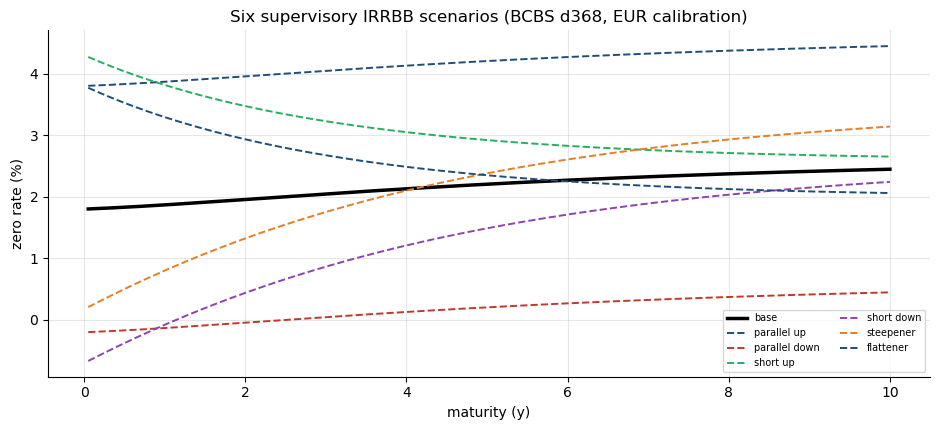

In [19]:
R_PAR, R_SHORT, R_LONG = 0.0200, 0.0250, 0.0100        # EUR calibration, BCBS d368 table 2
x = 4.0
shocks = {
    "parallel up":   lambda t: np.full_like(np.asarray(t, float),  R_PAR),
    "parallel down": lambda t: np.full_like(np.asarray(t, float), -R_PAR),
    "short up":      lambda t:  R_SHORT * np.exp(-np.asarray(t, float) / x),
    "short down":    lambda t: -R_SHORT * np.exp(-np.asarray(t, float) / x),
    "steepener":     lambda t: -0.65 * R_SHORT * np.exp(-np.asarray(t, float) / x)
                               + 0.90 * R_LONG * (1 - np.exp(-np.asarray(t, float) / x)),
    "flattener":     lambda t:  0.80 * R_SHORT * np.exp(-np.asarray(t, float) / x)
                               - 0.60 * R_LONG * (1 - np.exp(-np.asarray(t, float) / x)),
}
tt = np.linspace(0.05, 10, 200)
fig, ax = plt.subplots()
ax.plot(tt, ZERO(tt) * 100, "k-", lw=2.5, label="base")
for (lbl, f), c in zip(shocks.items(), PAL + PAL):
    ax.plot(tt, (ZERO(tt) + f(tt)) * 100, lw=1.4, ls="--", color=c, label=lbl)
ax.set_xlabel("maturity (y)"); ax.set_ylabel("zero rate (%)")
ax.set_title("Six supervisory IRRBB scenarios (BCBS d368, EUR calibration)")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

In [20]:
NOTIONAL = 10_000_000.0
TIER1    = 50_000_000.0     # ASSUMED Tier-1 base for the outlier ratio; not calibrated
SOT_EVE  = 0.15             # EBA/RTS/2022/10 supervisory outlier test on dEVE

CONTRACT = dict(zip(range(1, 6), BASE))     # each basket struck at its base fair spread

def book_npv(disc, s5_vec):
    # NPV to the PROTECTION SELLER of one unit of each k-th-to-default,
    # struck at the base fair spreads:  NPV_k = s*_k * RPV01 - DL.
    invs, _, _ = build_marginals(s5_vec, RECOVERY)
    U = be.gaussian_copula(CORR, 2 ** 14, "sobol", np.random.default_rng(SEED))
    r = be.price_basket(U, invs, RECOVERY, disc, payoff="brief")
    return np.array([CONTRACT[k] / 1e4 * r[k]["RPV01"] - r[k]["DL"]
                     for k in range(1, 6)]) * NOTIONAL

base_npv = book_npv(DISCOUNT, S5)

# the two risk factors are shocked ONE AT A TIME and kept in separate blocks:
# IRRBB moves the risk-free curve and holds the CDS strip;
# CSRBB moves the CDS strip and holds the risk-free curve.
irrbb, csrbb = {}, {}
for lbl, f in shocks.items():
    d = lambda t, f=f: np.exp(-(ZERO(t) + f(t)) * np.asarray(t, float))
    irrbb[lbl] = book_npv(d, S5) - base_npv
for bp in (50, 100, 200):
    csrbb[f"+{bp}bp spread"] = book_npv(DISCOUNT, S5 + bp) - base_npv

cols   = [f"{k}TD" for k in range(1, 6)]
EVE_IR = pd.DataFrame(irrbb, index=cols).T;  EVE_IR["BOOK total"] = EVE_IR.sum(axis=1)
EVE_CS = pd.DataFrame(csrbb, index=cols).T;  EVE_CS["BOOK total"] = EVE_CS.sum(axis=1)

# ---- reporting ----
print("dEVE in EUR, 10m-notional book, one unit of each k-th-to-default (protection SELLER)\n")
print("(a) IRRBB - six BCBS d368 supervisory scenarios; risk-free curve shocked, CDS strip held")
display(EVE_IR.round(0))
print("(b) CSRBB - market credit spread shocked; risk-free curve held")
display(EVE_CS.round(0))

w_ir = EVE_IR["BOOK total"].min()
w_cs = EVE_CS["BOOK total"].min()

print(f"\nSupervisory outlier test on dEVE applies to the IRRBB block ONLY.")
print(f"  worst IRRBB dEVE  EUR {w_ir:>12,.0f}   {abs(w_ir)/TIER1:8.4%} of Tier 1 "
      f"(assumed EUR {TIER1/1e6:.0f}m)   threshold {SOT_EVE:.0%}  -> "
      f"{'BREACH' if abs(w_ir)/TIER1 > SOT_EVE else 'no breach'}")
print(f"  worst CSRBB dEVE  EUR {w_cs:>12,.0f}   {abs(w_cs)/TIER1:8.4%} of the same base - "
      f"shown for monitoring only.")
print(f"  EBA/GL/2022/14 requires CSRBB to be identified, monitored and assessed, but sets no")
print(f"  numeric outlier threshold, so this ratio is NOT an SOT result.")
print(f"\n  |CSRBB| / |IRRBB| = {abs(w_cs/w_ir):,.0f}x  ->  on this book essentially all")
print(f"  economic-value risk is credit-spread risk, not interest-rate risk.")
print("\nSign check: the seller is short protection, so a spread widening is a LOSS; the IRRBB")
print("shocks act only through discounting, which is why they are ~600x smaller.")

dEVE in EUR, 10m-notional book, one unit of each k-th-to-default (protection SELLER)

(a) IRRBB - six BCBS d368 supervisory scenarios; risk-free curve shocked, CDS strip held


,1TD,2TD,3TD,4TD,5TD,BOOK total
parallel up,457.0,639.0,263.0,32.0,-1.0,1389.0
parallel down,-488.0,-703.0,-289.0,-36.0,1.0,-1515.0
short up,220.0,217.0,89.0,7.0,-0.0,532.0
short down,-231.0,-228.0,-94.0,-7.0,0.0,-559.0
steepener,-15.0,77.0,32.0,8.0,0.0,102.0
flattener,92.0,30.0,12.0,-3.0,-0.0,131.0


(b) CSRBB - market credit spread shocked; risk-free curve held


,1TD,2TD,3TD,4TD,5TD,BOOK total
+50bp spread,-151321.0,-65816.0,-20621.0,-4436.0,-530.0,-242723.0
+100bp spread,-276168.0,-131556.0,-49391.0,-11528.0,-1339.0,-469982.0
+200bp spread,-473534.0,-271005.0,-119696.0,-35772.0,-4849.0,-904855.0



Supervisory outlier test on dEVE applies to the IRRBB block ONLY.
  worst IRRBB dEVE  EUR       -1,515    0.0030% of Tier 1 (assumed EUR 50m)   threshold 15%  -> no breach
  worst CSRBB dEVE  EUR     -904,855    1.8097% of the same base - shown for monitoring only.
  EBA/GL/2022/14 requires CSRBB to be identified, monitored and assessed, but sets no
  numeric outlier threshold, so this ratio is NOT an SOT result.

  |CSRBB| / |IRRBB| = 597x  ->  on this book essentially all
  economic-value risk is credit-spread risk, not interest-rate risk.

Sign check: the seller is short protection, so a spread widening is a LOSS; the IRRBB
shocks act only through discounting, which is why they are ~600x smaller.


The two blocks are separated on purpose, and the separation is the point of the section.

The supervisory outlier test sits on the IRRBB block alone. EBA/RTS/2022/10 defines it as the
maximum decline in economic value across the six BCBS d368 scenarios, measured against Tier 1
capital, with the threshold at 15%. The worst of my six is the parallel-down shock at
EUR −1,515, which is 0.003% of the EUR 50m Tier-1 base I have assumed. No breach, and the
margin is so wide that the assumed base does not matter — any Tier 1 above about EUR 10,000
clears it.

The CSRBB block does not get compared to that threshold, and it would be wrong to do so.
EBA/GL/2022/14 requires an institution to identify, monitor and assess credit-spread risk in
the banking book, but it sets no numeric outlier test, so there is nothing here to breach. The
+200bp figure of EUR −904,855 is a monitoring number, not a supervisory result. I report the
ratio to Tier 1 only so the two blocks can be read on one scale.

What the split shows is worth more than either number alone. The worst credit-spread outcome
is roughly **600×** the worst interest-rate outcome. That is not a surprise once stated — the
position is short protection on five names, so its economic value is driven almost entirely by
where those five curves trade, while the risk-free curve enters only through discounting of a
five-year annuity that is close to par at inception. But it is exactly the decomposition a
supervisor asks for: separate the risk-free component from the credit-spread component, shock
one at a time, and show which one carries the book. Here it is unambiguously the second.

The sign is a useful check on the plumbing. The seller is short protection, so a spread
widening is a loss and every CSRBB row is negative. The IRRBB rows change sign with the
direction of the shock, since they move value only through discounting.

Two caveats on the numbers themselves. The book is repriced on 2¹⁴ paths rather than the 2¹⁶
used in SNo 6, so the 5TD column carries the same rare-event noise discussed in SNo 7 — at
EUR −4,849 on the worst row it is a rounding error against the book total, but I would not
quote it alone. And the Tier-1 base is an assumption with nothing behind it; the ratio scales
inversely with whatever figure a real institution would supply.

### 9.1 Mapping

| Notebook object | Regulatory counterpart |
|:---|:---|
| `ZERO` / `DISCOUNT` | IRRBB risk-free curve, shocked above |
| CDS strip &rarr; `bootstrap_hazards` &rarr; $Q(t)$ | CSRBB market-credit-spread term structure |
| $\Delta$EVE rows | economic-value impact of a spread widening |
| SNo 8.2 credit delta | idiosyncratic / migration spread sensitivity |
| SNo 8.1 correlation stress | dependence assumption, evidenced not assumed |
| SNo 5.3 MLE, SNo 7 gates | model-risk governance and reproducibility |

## 10. Core Takeaways, Weaknesses, and Next Steps

### What results are supporting
The best design choice here is the strict separation between the individual asset margins and the joint copula structure. The credit hazard curves are derived cleanly from the CDS strip and reprice it precisely to 0.0 bps, while the asset correlation comes entirely from historical equity returns. This makes swapping the copula a simple, one-line change, turning the comparison between the Gaussian and Student-t models into a smooth experiment. 

The validation pipeline was also built to fail big if something went wrong. The protection-leg identity holds down to a 0.0e+00 relative error across both copulas. Because this check avoids dividing by a risky annuity, any indexing flaws or sign errors in the sorting code would have broken it immediately. Meanwhile, the weaker spread-level sum misses by 7.9%. Having both metrics is intentional—hitting the exact gate while missing the approximate one proves that the residual stems from an annuity mismatch rather than a hard calculation bug. On the numerical side, using a scrambled Sobol' sequence successfully cut the standard error on the first-to-default (1TD) basket by 6.9×, verified across 12 independent runs. 

The most interesting finding is that holding the hazard rate ($\lambda$) fixed forces the credit spread to scale perfectly with the loss factor $(1-R)$. However, re-stripping the credit curves at each individual recovery rate ($R$) changes the final answer by a factor of thirty and even flips the sign on senior baskets. A higher assumed recovery forces the model to calculate a much higher default intensity just to match the same market spread—a nuance that is incredibly easy to miss.

### Limitations
Several limitations are hardcoded into the setup and cannot be fixed by just running more simulation paths. The Gaussian copula has zero tail dependence at any correlation $\rho < 1$, which is the exact flaw that made it fail during the 2008 crisis. The model is also entirely static—intensities, recoveries, and correlations are all treated as constants—which artificially drags senior spreads downward. There is also no counterparty credit risk modeled, which is a massive omission for a project analyzing AIG.

On the calibration side the weak points are:

* Equity returns are only a proxy for default dependence.
* Average correlation came out at 0.212. That is low versus the usual 40-60% numbers people quote, but it is what the data gave   me. TotalEnergies really did move quite independently of the auto and bank names in this window. A same-sector basket would     look different.
* $\hat\nu$= 17.86 sits on a very flat likelihood. 156 weekly observations with no major stress event is not a lot of             information. Adding March 2020 would almost certainly pull $\hat\nu$ down.
* GPD tails are fitted on roughly 16 points each. Deutsche Bank’s shape parameter went to –1.246, which is outside the usual       range, and there is a small jump where the KDE interior meets the GPD.
* I used the same curve shape for all five names (just scaled). In reality the term structures would differ.

### Extensions
My immediate priority is implementing importance sampling. Applying an exponential tilt to the cumulative hazard distribution would force the simulation to focus its draws exactly where the senior payoff actually lives. When you are dealing with a tiny 0.008% trigger probability, shifting where the paths are drawn is the mathematically sound solution, rather than just forcing brute-force computational power at the problem.

Beyond that, I plan to roll out a few specific upgrades:
1. **Clayton Copula:** Both models used here are radially symmetric, which completely misses the stark downward asymmetry seen in real-world credit defaults.
2. **External Benchmark:** Build a semi-analytic Hull-White script to serve as an external sanity check sharing zero code with this repository.
3. **Dynamic Parameters:** Introduce stochastic recovery rates that correlate directly with our systematic market factor, alongside CVA on the protection seller to account for wrong-way risk.

Finally, this architecture scales easily to standard credit tranches. By swapping out the simple $k$th-order statistic for a dedicated attachment and detachment loss function, this script pivots into a full CDO pricing tool where we can feed the model base correlations directly from quoted iTraxx tranches.


## 11. Conclusion and references


### Conclusion

I set out to price the full $k$th-to-default ladder on five European corporates under Gaussian and Student-$t$ copulas, with marginals stripped from CDS curves and dependence estimated from three years of weekly equity returns.

Under the brief's convention the spreads come out at 65.10, 13.61, 2.88, 0.37 and 0.022 bps for the Gaussian, and 63.01, 14.48, 3.41, 0.57 and 0.047 for the $t$ at $\hat\nu = 17.86$, on $2^{16}$ scrambled Sobol' paths. The ladder is monotone under both and the first-to-default sits inside its bounds of [24.00, 76.00] bps.

Three things came out of this that I hadn't fully appreciated before starting.

* Dependence moves risk around the ladder without changing how much there is. The summed protection legs differ by 0.087%         between the two copulas while individual instruments differ by up to 114%. Total expected loss is fixed by the marginals;       correlation only decides which layer absorbs it.

* The sign of correlation exposure depends on seniority. A move to $\rho = 0.90$ takes the 1TD from 65.10 to 31.74 bps and the     5TD from 0.022 to 4.82 — a factor of 220 in the opposite direction. "Long correlation" means nothing here without naming the     tranche.

* And recovery sensitivity reverses once you re-bootstrap the curves, because $\lambda \approx s/(1-R)$ has to keep reproducing   the observed spread. Holding $\lambda$ fixed measures an identity, not a sensitivity. That one took me a while to see.

On what I can and can't stand behind: the marginals reprice their input strip exactly, the density matches an independent construction to 7.99e-15, and the protection-leg identity holds to zero error. The calibration is thinner. A likelihood ratio of 2.4 on 156 observations with no systemic event in the window is weak evidence for anything, the GPD tails are fitted on too few exceedances, and the 5TD triggers on one path in 12,945.

In the end a basket CDS is mainly a view on how clustered the defaults will be. That parameter is hard to estimate from history and tends to jump in a crisis. The stress tests in Section 8 are therefore not an optional extra — for the senior contracts 
they are the main result.

### References

1. Dr R. Diamond, JA26W1 Final Project Workshop I (CQF)
2. R. Ahmed, JA26T9 Final Project Tutorial II (CQF)
3. Dr. Si-Yi Zhou, JA266.12 CDO & Correlation Sensitivity (CQF)
4. Dr R. Diamond, JA26P16 Intensity Models (CQF)
5. Dr R. Diamond, JA26P17 CDS Pricing (CQF)
6. MathWorks, Nonparametric Estimates of Cumulative Distribution Functions and Their Inverses
7. MathWorks, Using Extreme Value Theory and Copulas to Evaluate Market Risk
8. BCBS, *Interest Rate Risk in the Banking Book*, d368, April 2016
9. EBA, *Guidelines on IRRBB and CSRBB*, EBA/GL/2022/14, 2022
---
*Engine: `basket_engine.py`